In [3]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(
    model="auto",
    base_url="http://127.0.0.1:31415/v1",
    api_key=os.getenv("FREELLMAPI_API_KEY"),
    temperature=0
)

response = llm.invoke("Explain LangGraph in simple words.")

print(response.content)



Of course! Let's explain LangGraph in simple words.

### The Simple Analogy: A Recipe with Checkpoints

Imagine you're making a complex recipe, like a gourmet meal. A normal recipe is a **straight line**:

1.  Chop vegetables.
2.  Boil water.
3.  Cook pasta.
4.  Make sauce.
5.  Combine and serve.

This is how most AI "chains" work. They follow a set, linear path.

Now, imagine a **smart, robotic chef**. This chef is smart enough to:
*   **Check its work.** After boiling water, it checks if the pasta is cooked. If not, it goes back to the "boil" step.
*   **Make decisions.** If the sauce is too thin, it might decide to "reduce sauce" instead of moving to "combine."
*   **Handle mistakes.** If it burns the sauce, it can start that part over from the "make sauce" step.

**LangGraph is the software that lets you build this smart, robotic chef.** It's a tool for creating AI agents that can loop, make decisions, and remember their state (like a chef remembering the water is already boiling

In [11]:
from openai import OpenAI

client = OpenAI(
    base_url="http://127.0.0.1:31415/v1",
    api_key="freellmapi-5f091826027f3b03389676d99b401709aa8f509a52bf3b5e"

)

response = client.chat.completions.create(
    model="auto",
    messages=[
        {"role": "user", "content": "Explain LangGraph in simple words."}
    ]
)

print(response.choices[0].message.content)



Of course! Let's explain LangGraph using a simple analogy: **making a spaghetti sauce.**

### The Core Idea in One Sentence

**LangGraph is a way to build AI agents that can follow a plan or a recipe, step-by-step, instead of just giving one-off answers.**

---

### The Analogy: The "Smart Sauce" Recipe

Imagine you want to build an AI Chef that can make a spaghetti sauce from scratch. A normal AI might just tell you the steps, but it wouldn't *do* anything. LangGraph lets you build an AI that actually *cooks*.

Here’s how the LangGraph recipe works:

1.  **The Ingredients (The "State"):**
    *   This is the shared memory or the current situation. It's a list that holds everything the AI Chef knows and has done.
    *   **Example State:** `{"ingredients": ["tomatoes", "onion", "garlic"], "chopped": False, "sauce_ready": False}`

2.  **The Recipe Steps (The "Nodes"):**
    *   These are the actions or functions the AI can perform. Each node takes the current state, does something, an

In [39]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.checkpoint.memory import MemorySaver


In [18]:
#deining the state graph for the chatbot workflow
from langgraph.graph import add_messages
class Chatbot(TypedDict):
    message: Annotated[list[BaseMessage], add_messages]

In [19]:
def chat_node(state:Chatbot):
    #takes user query from state
    messages=state['message']
    #send the messages to the llm and get the response
    response=llm.invoke(messages)
    #aresponse stored in the state
    return {'message': [response]}


In [41]:
CheckpointSaver=MemorySaver()
#adding node 
graph=StateGraph(Chatbot)
graph.add_node('chat_node',chat_node)

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)



In [43]:
workflow=graph.compile(checkpointer=CheckpointSaver)

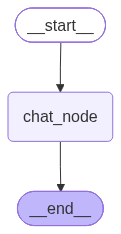

In [22]:
workflow

In [23]:
initial_state={
    'message':[HumanMessage(content="Explain LangGraph in simple words.")]
}
response=workflow.invoke(initial_state)


In [37]:
response['message'][-1].content


'\n\nOf course! Let\'s explain LangGraph using a simple analogy: **Planning a Vacation**.\n\n### The Core Idea in One Sentence\n\n**LangGraph is a tool for building AI applications that can think and act in steps, just like a human would.**\n\nIt lets you create a "flowchart" for your AI, where it can make decisions, use tools, and remember what it has done.\n\n---\n\n### The Vacation Planning Analogy\n\nImagine you are an AI vacation planner. Your goal is to book a perfect trip for a user. A simple, rigid program would have a fixed list of steps:\n\n1.  Ask for destination.\n2.  Ask for dates.\n3.  Search for flights.\n4.  Search for hotels.\n5.  Book everything.\n\nBut what if the user changes their mind? Or what if there are no flights? A simple program would get stuck.\n\n**This is where LangGraph comes in.** It lets you build a *smart* planner.\n\n### The LangGraph "Flowchart"\n\nThink of LangGraph as a flowchart with two main ingredients:\n\n1.  **Nodes (The Steps):** These are t

In [45]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

while True:
    user_message = input("User: ")

    if user_message.lower().strip() in ["exit", "quit", "q", "bye"]:
        print("Exiting the chatbot.")
        break

    response = workflow.invoke(
        {'message': [HumanMessage(content=user_message)]},
        config=config
    )

    print("AI:",response['message'][-1].content)

AI: 

Hello! I'm dots, an AI model developed by Dots Studio at rednote. How can I help you today?
AI: 

Nice to meet you, Jeff! I'll remember your name. What can I help you with today?
AI: 

You haven't shared the meme yet — could you paste the image or a link to it? Once I can see it, I'll dig into where it came from.
AI: 

I remember, Jeff — nice to meet you again! Still waiting on that meme you asked about earlier — feel free to paste it or link it whenever you're ready, and I'll trace its origins for you.
AI: 

Ah, that one! The "My name is Jeff" meme comes from a deadpan YouTube video uploaded back in 2006 by a guy named Jeff (the original channel was something like "jeffreymh"). In the clip, he just holds up a sign that says "my name is jeff" and says it flatly, with this oddly intense, unblinking stare — no context, no explanation, just pure awkward sincerity.

It exploded across the internet in the late 2000s and early 2010s. People remixed it, dubbed it over movie scenes, used